In [ ]:
# =====================================================================
# SISTEM DETEKSI PNEUMONIA DARI SUARA BATUK — v3.0
# Pipeline: LogMMSE → Adaptive Segmentation → 80-dim MFCC →
#           AE Feature Extractor → One-Class SVM → LOO-CV Evaluation
# =====================================================================
#
# DESIGN DECISIONS v3:
# 1. Segmentasi  → Adaptive threshold: 0.2 * max_energy + fallback jika gagal
# 2. Threshold   → Relatif per file, bukan fixed 0.02
# 3. Augmentasi  → Aggregate original dulu, augmentasi expand training set (Option A)
# 4. Trimming    → Pad ke fixed_len sebelum MFCC, tidak ada trimming ulang
# 5. Feature vec → 80 fitur: mean + std + skew + kurtosis (20 coef x 4 stat)
# 6. Autoencoder → <50k params: Dense(64)→Dense(32)→Latent(4) (feature extractor)
# 7. Evaluasi    → Leave-One-Out Cross Validation (n=82)
# 8. AE threshold→ Dari validation set distribution
# 9. Noise reduce→ prop_decrease=0.4
# 10. Pitch shift → ±1 semitone (lebih realistis)
# ARSITEKTUR FINAL:
#   Audio → Preprocess → Segment → MFCC → Autoencoder (latent) → One-Class SVM
# =====================================================================

In [ ]:
# ─────────────────────────────────────────────
# CELL 1: INSTALASI
# ─────────────────────────────────────────────
!unzip /content/pneumonia.zip -d /content/pneumonia
!pip install librosa scikit-learn tensorflow keras joblib numpy pandas \
    matplotlib seaborn soundfile tqdm scipy noisereduce

unzip:  cannot find or open /content/pneumonia.zip, /content/pneumonia.zip.zip or /content/pneumonia.zip.ZIP.


In [ ]:
# ─────────────────────────────────────────────
# CELL 2: MOUNT DRIVE
# ─────────────────────────────────────────────
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ─────────────────────────────────────────────
# CELL 3: IMPORT LIBRARY
# ─────────────────────────────────────────────
import os
import json
import warnings
import logging
from pathlib import Path
from datetime import datetime
from typing import Optional, Tuple, List, Dict, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm import tqdm
from scipy import signal as scipy_signal
from scipy.io import wavfile
from scipy.stats import skew, kurtosis

# Audio
import librosa
import librosa.display
import soundfile as sf
import noisereduce as nr

# Machine Learning
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
import joblib

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Config
warnings.filterwarnings('ignore')
logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')
logger = logging.getLogger(__name__)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
plt.style.use('seaborn-v0_8-darkgrid')

print("✅ Semua library berhasil diimport!")
print(f"   TensorFlow : {tf.__version__}")
print(f"   Librosa    : {librosa.__version__}")
print(f"   NumPy      : {np.__version__}")

✅ Semua library berhasil diimport!
   TensorFlow : 2.20.0
   Librosa    : 0.11.0
   NumPy      : 2.0.2


In [ ]:
# ─────────────────────────────────────────────
# CELL 4: KONFIGURASI GLOBAL
# ─────────────────────────────────────────────
class Config:
    """Pusat konfigurasi pipeline v3 — semua perubahan desain di sini."""

    # --- Path ---
    DATA_DIR   = Path("pneumonia")
    OUTPUT_DIR = Path("/content/drive/MyDrive/Pneumonia Analysis/output_v3")
    MODEL_DIR  = Path("/content/drive/MyDrive/Pneumonia Analysis/output_v3/models")

    # --- Audio Pre-processing ---
    SAMPLE_RATE        = 22050
    # v3: prop_decrease diturunkan ke 0.4 (lebih konservatif)
    NOISE_REDUCE_PROP  = 0.4
    NOISE_STATIONARY   = True

    # --- Cough Segmentation (Adaptive Threshold) ---
    # v3: threshold = ADAPTIVE_RATIO * max_energy per file
    ENERGY_FRAME_LEN    = 512
    ENERGY_HOP          = 128
    ADAPTIVE_RATIO      = 0.20   # 20% dari peak energy file
    FALLBACK_RATIO      = 0.05   # Fallback jika 0.20 terlalu agresif (0 chunks)
    MIN_CHUNK_DUR       = 0.1
    MAX_CHUNK_DUR       = 2.0
    MERGE_GAP           = 0.05

    # --- Data Augmentation ---
    # v3: pitch ±1 semitone (lebih realistis)
    TS_MAX_SHIFT = 0.2
    TS_N         = 2
    PS_STEPS     = [-1, 1]        # ← diubah dari [-2,2] ke [-1,1]
    NA_FACTOR    = 0.005
    NA_N         = 2

    # --- Feature Extraction ---
    # v3: 80-dim = 20 MFCC × 4 statistik (mean, std, skew, kurtosis)
    N_MFCC     = 20
    N_FFT      = 2048
    HOP_LENGTH = 512
    FMIN       = 50
    FMAX       = 8000
    FIXED_LEN  = 22050            # 1 detik @ 22050 Hz

    # --- Autoencoder (Feature Extractor) ---
    # v3: arsitektur kecil <50k param
    AE_LATENT_DIM  = 4            # ← diubah dari 8 ke 4
    AE_EPOCHS      = 200
    AE_BATCH_SIZE  = 8
    AE_LR          = 1e-3
    AE_THRESHOLD_PCT = 95

    # --- One-Class SVM ---
    OCSVM_NU     = 0.1
    OCSVM_KERNEL = 'rbf'
    OCSVM_GAMMA  = 'scale'

    # --- Evaluasi ---
    # v3: Leave-One-Out Cross Validation
    EVAL_METHOD = 'LOO'

    FEATURE_DIM = N_MFCC * 4     # 80


for d in [Config.OUTPUT_DIR, Config.MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("✅ Konfigurasi v3 dimuat!")
print(f"   Feature dim      : {Config.FEATURE_DIM} (20 MFCC × 4 stats)")
print(f"   Adaptive ratio   : {Config.ADAPTIVE_RATIO}")
print(f"   Noise prop       : {Config.NOISE_REDUCE_PROP}")
print(f"   Pitch steps      : {Config.PS_STEPS}")
print(f"   AE latent dim    : {Config.AE_LATENT_DIM}")

✅ Konfigurasi v3 dimuat!
   Feature dim      : 80 (20 MFCC × 4 stats)
   Adaptive ratio   : 0.2
   Noise prop       : 0.4
   Pitch steps      : [-1, 1]
   AE latent dim    : 4


In [ ]:
# ─────────────────────────────────────────────
# CELL 5: PRE-PROCESSING
# ─────────────────────────────────────────────
def logmmse_noise_reduction(
    audio: np.ndarray,
    sr: int = Config.SAMPLE_RATE,
    prop_decrease: float = Config.NOISE_REDUCE_PROP,
    stationary: bool = Config.NOISE_STATIONARY
) -> np.ndarray:
    """Noise reduction berbasis spectral estimation (LogMMSE-like via noisereduce)."""
    try:
        audio_denoised = nr.reduce_noise(
            y=audio, sr=sr,
            prop_decrease=prop_decrease,
            stationary=stationary,
            n_fft=512, n_jobs=1
        )
        return audio_denoised.astype(np.float32)
    except Exception as e:
        logger.warning(f"Noise reduction gagal, pakai audio asli: {e}")
        return audio


def normalize_amplitude(audio: np.ndarray) -> np.ndarray:
    """Peak normalization: max abs = 1.0"""
    max_val = np.max(np.abs(audio))
    if max_val > 1e-8:
        return (audio / max_val).astype(np.float32)
    return audio.astype(np.float32)


def preprocess_audio(filepath: str, sr: int = Config.SAMPLE_RATE) -> Optional[np.ndarray]:
    """Pipeline prapemrosesan: Load → Mono → LogMMSE → Normalize"""
    try:
        audio, _ = librosa.load(filepath, sr=sr, mono=True)
        if len(audio) == 0:
            logger.warning(f"File kosong: {filepath}")
            return None
        audio = logmmse_noise_reduction(audio, sr)
        audio = normalize_amplitude(audio)
        return audio
    except Exception as e:
        logger.error(f"Gagal preprocess {filepath}: {e}")
        return None

In [ ]:
# ─────────────────────────────────────────────
# CELL 6: ADAPTIVE COUGH SEGMENTATION
# ─────────────────────────────────────────────
def compute_frame_energy(
    audio: np.ndarray,
    frame_len: int = Config.ENERGY_FRAME_LEN,
    hop: int = Config.ENERGY_HOP
) -> np.ndarray:
    """Hitung RMS energy per frame."""
    rms = librosa.feature.rms(
        y=audio, frame_length=frame_len,
        hop_length=hop, center=True
    )
    return rms[0]


def _extract_chunks_from_mask(
    audio: np.ndarray, energy: np.ndarray,
    energy_threshold: float, hop: int,
    sr: int, min_dur: float, max_dur: float, merge_gap: float
) -> List[np.ndarray]:
    """
    Helper: ekstrak chunk dari active mask berdasarkan threshold tertentu.
    Mengembalikan list chunk (bisa kosong jika tidak ada yang lolos).
    """
    active_mask = energy > energy_threshold
    intervals_samples = []
    in_chunk = False
    chunk_start = 0

    for i, is_active in enumerate(active_mask):
        sample_pos = i * hop
        if is_active and not in_chunk:
            chunk_start = sample_pos
            in_chunk = True
        elif not is_active and in_chunk:
            intervals_samples.append((chunk_start, min(sample_pos, len(audio))))
            in_chunk = False
    if in_chunk:
        intervals_samples.append((chunk_start, len(audio)))

    if not intervals_samples:
        return []

    # Merge gaps
    gap_samples = int(merge_gap * sr)
    merged = [intervals_samples[0]]
    for start, end in intervals_samples[1:]:
        prev_start, prev_end = merged[-1]
        if start - prev_end <= gap_samples:
            merged[-1] = (prev_start, end)
        else:
            merged.append((start, end))

    # Filter durasi
    min_samples = int(min_dur * sr)
    max_samples = int(max_dur * sr)
    chunks = []
    for start, end in merged:
        dur = end - start
        if dur < min_samples:
            continue
        if dur > max_samples:
            center = (start + end) // 2
            start = max(0, center - max_samples // 2)
            end   = min(len(audio), start + max_samples)
        chunks.append(audio[start:end].astype(np.float32))

    return chunks


def segment_cough_chunks(
    audio: np.ndarray,
    sr: int = Config.SAMPLE_RATE,
    adaptive_ratio: float = Config.ADAPTIVE_RATIO,
    fallback_ratio: float = Config.FALLBACK_RATIO,
    frame_len: int = Config.ENERGY_FRAME_LEN,
    hop: int = Config.ENERGY_HOP,
    min_dur: float = Config.MIN_CHUNK_DUR,
    max_dur: float = Config.MAX_CHUNK_DUR,
    merge_gap: float = Config.MERGE_GAP
) -> List[np.ndarray]:
    """
    v3: Adaptive threshold segmentation.
    Threshold = adaptive_ratio × max_energy per file.
    Fallback ke fallback_ratio jika hasilnya 0 chunk.
    Fallback terakhir: seluruh sinyal sebagai 1 chunk.
    """
    energy = compute_frame_energy(audio, frame_len, hop)
    max_energy = np.max(energy)

    if max_energy < 1e-8:
        logger.warning("Energi sinyal sangat rendah, gunakan seluruh sinyal")
        return [audio]

    # Coba adaptive threshold utama
    threshold = adaptive_ratio * max_energy
    chunks = _extract_chunks_from_mask(
        audio, energy, threshold, hop, sr, min_dur, max_dur, merge_gap
    )

    # Fallback: threshold lebih rendah
    if not chunks:
        threshold_fb = fallback_ratio * max_energy
        logger.warning(
            f"Adaptive thr={threshold:.4f} → 0 chunk. "
            f"Fallback thr={threshold_fb:.4f}"
        )
        chunks = _extract_chunks_from_mask(
            audio, energy, threshold_fb, hop, sr, min_dur, max_dur, merge_gap
        )

    # Fallback final: seluruh sinyal
    if not chunks:
        logger.warning("Tetap 0 chunk setelah fallback, gunakan seluruh sinyal")
        return [audio]

    return chunks

In [ ]:
# ─────────────────────────────────────────────
# CELL 7: DATA AUGMENTATION
# ─────────────────────────────────────────────
def augment_time_shift(audio: np.ndarray, max_shift: float = Config.TS_MAX_SHIFT) -> np.ndarray:
    shift = int(np.random.uniform(-max_shift, max_shift) * len(audio))
    if shift == 0:
        return audio.copy()
    result = np.zeros_like(audio)
    if shift > 0:
        result[shift:] = audio[:-shift]
    else:
        result[:shift] = audio[-shift:]
    return result.astype(np.float32)


def augment_pitch_shift(
    audio: np.ndarray,
    sr: int = Config.SAMPLE_RATE,
    n_steps: float = 1.0
) -> np.ndarray:
    """v3: ±1 semitone (lebih realistis dari ±2)"""
    try:
        shifted = librosa.effects.pitch_shift(y=audio, sr=sr, n_steps=n_steps)
        return normalize_amplitude(shifted)
    except Exception as e:
        logger.warning(f"Pitch shift gagal: {e}")
        return audio.copy()


def augment_add_noise(audio: np.ndarray, noise_factor: float = Config.NA_FACTOR) -> np.ndarray:
    noise = np.random.normal(0, noise_factor, len(audio)).astype(np.float32)
    return normalize_amplitude(audio + noise)


def augment_chunk(
    chunk: np.ndarray,
    sr: int = Config.SAMPLE_RATE,
    n_time_shifts: int = Config.TS_N,
    pitch_steps: List[float] = Config.PS_STEPS,
    n_noise: int = Config.NA_N
) -> List[np.ndarray]:
    """
    v3: Augmentasi tanpa menyertakan original.
    Original sudah di-aggregate terlebih dahulu (Option A).
    Returns hanya variasi augmented.
    """
    augmented = []
    for _ in range(n_time_shifts):
        augmented.append(augment_time_shift(chunk))
    for steps in pitch_steps:
        augmented.append(augment_pitch_shift(chunk, sr, steps))
    for _ in range(n_noise):
        augmented.append(augment_add_noise(chunk))
    return augmented

In [ ]:
# ─────────────────────────────────────────────
# CELL 8: FEATURE EXTRACTION (80-dim)
# ─────────────────────────────────────────────
def pad_or_crop_chunk(chunk: np.ndarray, target_len: int = Config.FIXED_LEN) -> np.ndarray:
    """
    v3: Selalu pad/crop ke fixed_len SEBELUM MFCC.
    Crop dari tengah jika panjang, pad 0 di kanan jika pendek.
    """
    if len(chunk) >= target_len:
        start = (len(chunk) - target_len) // 2
        return chunk[start:start + target_len]
    else:
        return np.pad(chunk, (0, target_len - len(chunk)), mode='constant').astype(np.float32)


def extract_mfcc_matrix(
    chunk: np.ndarray,
    sr: int = Config.SAMPLE_RATE,
    n_mfcc: int = Config.N_MFCC,
    fixed_len: int = Config.FIXED_LEN
) -> np.ndarray:
    """Ekstrak matriks MFCC (n_mfcc, T) dari satu chunk."""
    chunk_fixed = pad_or_crop_chunk(chunk, fixed_len)
    mfcc = librosa.feature.mfcc(
        y=chunk_fixed, sr=sr, n_mfcc=n_mfcc,
        n_fft=Config.N_FFT, hop_length=Config.HOP_LENGTH,
        fmin=Config.FMIN, fmax=Config.FMAX
    )
    return mfcc.astype(np.float32)


def mfcc_to_80dim_vector(mfcc_matrix: np.ndarray) -> np.ndarray:
    """
    v3: Konversi matriks MFCC (20, T) → 80-dim vektor.
    4 statistik per koefisien: mean, std, skew, kurtosis.
    """
    mean_vec = np.mean(mfcc_matrix, axis=1)             # (20,)
    std_vec  = np.std(mfcc_matrix, axis=1)              # (20,)
    skew_vec = skew(mfcc_matrix, axis=1)                # (20,)
    kurt_vec = kurtosis(mfcc_matrix, axis=1)            # (20,)
    return np.concatenate([mean_vec, std_vec, skew_vec, kurt_vec]).astype(np.float32)  # (80,)


def aggregate_mfcc_chunks(mfcc_list: List[np.ndarray]) -> np.ndarray:
    """
    Aggregation Operation (Eq.1 paper): rata-rata matriks MFCC semua chunk.
    Input : list matriks (20, T) dengan T sama
    Output: matriks (20, T)
    """
    if not mfcc_list:
        raise ValueError("mfcc_list kosong")
    stacked = np.stack(mfcc_list, axis=0)    # (N, 20, T)
    return np.mean(stacked, axis=0).astype(np.float32)   # (20, T)

In [ ]:
# ─────────────────────────────────────────────
# CELL 9: BUILD DATASET (Option A - Augmentasi expand training)
# ─────────────────────────────────────────────
def build_dataset_option_a(
    audio_files: List[Path],
    sr: int = Config.SAMPLE_RATE
) -> Tuple[np.ndarray, List[str]]:
    """
    v3 Option A: Aggregate original dulu, augmentasi hanya expand training set.

    Per file:
    1. Preprocess → Segment → Ekstrak MFCC per chunk
    2. Aggregate MFCC chunks → 1 representasi original per pasien (80-dim)
    3. Augmentasi SETIAP CHUNK → MFCC → Aggregate augmented → tambahan sampel

    Returns:
        X        : feature matrix (N_total, 80)
        origins  : list ('P1.mp3', 'P1.mp3_aug1', ...) untuk tracking
    """
    X_list       = []
    origins_list = []
    failed_files = []

    print(f"📂 Memproses {len(audio_files)} file audio (Option A)...")

    for filepath in tqdm(audio_files, desc="Build Dataset v3"):
        try:
            # Step 1: Preprocess
            audio = preprocess_audio(str(filepath), sr)
            if audio is None:
                failed_files.append(filepath.name)
                continue

            # Step 2: Segment
            chunks = segment_cough_chunks(audio, sr)

            # Step 3: MFCC per chunk original
            mfcc_originals = [extract_mfcc_matrix(c, sr) for c in chunks]

            # Seragamkan T (frame) di antara chunk
            min_T = min(m.shape[1] for m in mfcc_originals)
            mfcc_originals_trimmed = [m[:, :min_T] for m in mfcc_originals]

            # Step 4: Aggregate original → 1 representasi per pasien
            agg_original = aggregate_mfcc_chunks(mfcc_originals_trimmed)
            feat_original = mfcc_to_80dim_vector(agg_original)
            X_list.append(feat_original)
            origins_list.append(filepath.name)

            # Step 5: Augmentasi setiap chunk → tambahan sampel
            # Kumpulkan semua chunk augmented
            aug_chunks_all = []
            for chunk in chunks:
                aug_variants = augment_chunk(chunk, sr)  # tidak include original
                aug_chunks_all.extend(aug_variants)

            if aug_chunks_all:
                # Ekstrak MFCC augmented
                mfcc_augs = [extract_mfcc_matrix(c, sr) for c in aug_chunks_all]
                min_T_aug = min(m.shape[1] for m in mfcc_augs)
                mfcc_augs_trimmed = [m[:, :min_T_aug] for m in mfcc_augs]

                # Aggregate semua augmented → 1 representasi augmented per pasien
                agg_aug = aggregate_mfcc_chunks(mfcc_augs_trimmed)
                feat_aug = mfcc_to_80dim_vector(agg_aug)
                X_list.append(feat_aug)
                origins_list.append(f"{filepath.name}_aug")

        except Exception as e:
            logger.error(f"Error pada {filepath.name}: {e}")
            failed_files.append(filepath.name)

    if failed_files:
        print(f"\n⚠️  {len(failed_files)} file gagal: {failed_files}")

    X = np.array(X_list, dtype=np.float32)
    print(f"\n✅ Dataset berhasil dibangun (Option A):")
    print(f"   Total sampel   : {X.shape[0]} ({len(audio_files)} original + augmented)")
    print(f"   Feature dim    : {X.shape[1]}")
    return X, origins_list

In [ ]:
# ─────────────────────────────────────────────
# CELL 10: BANGUN DATASET ORIGINAL (tanpa augmentasi) untuk LOO-CV
# ─────────────────────────────────────────────
def build_dataset_original_only(
    audio_files: List[Path],
    sr: int = Config.SAMPLE_RATE
) -> Tuple[np.ndarray, List[str]]:
    """Dataset tanpa augmentasi — untuk evaluasi LOO-CV yang adil."""
    X_list    = []
    names_list = []
    failed    = []

    for filepath in tqdm(audio_files, desc="Build Original Dataset"):
        try:
            audio = preprocess_audio(str(filepath), sr)
            if audio is None:
                failed.append(filepath.name)
                continue
            chunks = segment_cough_chunks(audio, sr)
            mfcc_list = [extract_mfcc_matrix(c, sr) for c in chunks]
            min_T = min(m.shape[1] for m in mfcc_list)
            mfcc_trimmed = [m[:, :min_T] for m in mfcc_list]
            agg = aggregate_mfcc_chunks(mfcc_trimmed)
            feat = mfcc_to_80dim_vector(agg)
            X_list.append(feat)
            names_list.append(filepath.name)
        except Exception as e:
            logger.error(f"Error {filepath.name}: {e}")
            failed.append(filepath.name)

    if failed:
        print(f"⚠️  {len(failed)} file gagal: {failed}")

    X = np.array(X_list, dtype=np.float32)
    print(f"\n✅ Dataset original: {X.shape[0]} sampel × {X.shape[1]} fitur")
    return X, names_list

In [ ]:
# ─────────────────────────────────────────────
# CELL 11: AUTOENCODER (Feature Extractor) — <50k params
# ─────────────────────────────────────────────
def build_autoencoder_v3(
    input_dim: int,
    latent_dim: int = Config.AE_LATENT_DIM,
    lr: float = Config.AE_LR
) -> Tuple[Model, Model, Model]:
    """
    v3: Autoencoder kecil <50k params sebagai feature extractor.
    Arsitektur: Input(80) → Dense(64) → Dense(32) → Latent(4)
                         → Dense(32) → Dense(64) → Output(80)

    Latent layer = representasi terkompresi untuk SVM.
    """
    # --- ENCODER ---
    enc_in = layers.Input(shape=(input_dim,), name='enc_input')
    x = layers.Dense(64, name='enc_d1')(enc_in)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.15)(x)

    x = layers.Dense(32, name='enc_d2')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    x = layers.Dropout(0.15)(x)

    latent = layers.Dense(latent_dim, activation='relu', name='latent')(x)
    encoder = Model(enc_in, latent, name='encoder')

    # --- DECODER ---
    dec_in = layers.Input(shape=(latent_dim,), name='dec_input')
    y = layers.Dense(32, name='dec_d1')(dec_in)
    y = layers.BatchNormalization()(y)
    y = layers.Activation('relu')(y)
    y = layers.Dropout(0.15)(y)

    y = layers.Dense(64, name='dec_d2')(y)
    y = layers.BatchNormalization()(y)
    y = layers.Activation('relu')(y)

    dec_out = layers.Dense(input_dim, activation='sigmoid', name='dec_output')(y)
    decoder = Model(dec_in, dec_out, name='decoder')

    # --- AUTOENCODER ---
    ae_in  = layers.Input(shape=(input_dim,), name='ae_input')
    ae_out = decoder(encoder(ae_in))
    autoencoder = Model(ae_in, ae_out, name='autoencoder_v3')
    autoencoder.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='mse', metrics=['mae']
    )
    return autoencoder, encoder, decoder


def train_autoencoder(
    X_train: np.ndarray,
    X_val: np.ndarray,
    input_dim: int,
    save_path: Optional[str] = None
) -> Tuple[Model, Model, Any]:
    """Latih autoencoder dan kembalikan (autoencoder, encoder, history)."""
    autoencoder, encoder, decoder = build_autoencoder_v3(input_dim)

    callbacks_ae = [
        EarlyStopping(monitor='val_loss', patience=20,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                          patience=8, min_lr=1e-6, verbose=0)
    ]
    if save_path:
        callbacks_ae.append(
            ModelCheckpoint(save_path, monitor='val_loss',
                            save_best_only=True, verbose=0)
        )

    history = autoencoder.fit(
        X_train, X_train,
        epochs=Config.AE_EPOCHS,
        batch_size=Config.AE_BATCH_SIZE,
        validation_data=(X_val, X_val),
        callbacks=callbacks_ae,
        verbose=0,
        shuffle=True
    )
    return autoencoder, encoder, history

In [ ]:
# ─────────────────────────────────────────────
# CELL 12: LEAVE-ONE-OUT CROSS VALIDATION
# ─────────────────────────────────────────────
def run_loo_cv(
    X_orig: np.ndarray,
    filenames: List[str],
    X_aug: Optional[np.ndarray] = None,
    aug_origins: Optional[List[str]] = None,
    verbose: bool = False
) -> pd.DataFrame:
    """
    v3: Leave-One-Out Cross Validation (n=82).

    Untuk setiap fold i:
    - Test  : sampel ke-i (original saja)
    - Train : semua sampel KECUALI sampel ke-i (original + augmented)
              Augmented dari file ke-i JUGA dikeluarkan dari training.

    Pipeline per fold:
    1. MinMaxScaler fit pada training set
    2. Autoencoder dilatih pada training set (scaled)
    3. Latent representation di-extract (AE sebagai feature extractor)
    4. StandardScaler fit pada latent train
    5. One-Class SVM dilatih pada latent train (scaled)
    6. Prediksi pada test sample
    7. AE threshold dihitung dari training reconstruction error (P95)

    Returns:
        DataFrame hasil per sampel
    """
    n = len(X_orig)
    results = []

    print(f"🔄 LOO-CV: {n} fold...")

    for i in tqdm(range(n), desc="LOO-CV"):
        # ── Pisahkan train / test ──
        test_feat   = X_orig[i:i+1]          # shape (1, 80)
        test_name   = filenames[i]

        # Train: semua original kecuali i
        idx_train = [j for j in range(n) if j != i]
        X_train_orig = X_orig[idx_train]

        # Tambahkan augmented (kecuali augmented dari file ke-i)
        if X_aug is not None and aug_origins is not None:
            test_stem = filenames[i].replace('.mp3', '').replace('.wav', '')
            aug_mask  = [
                j for j, name in enumerate(aug_origins)
                if test_stem not in name
            ]
            X_train_aug = X_aug[aug_mask] if aug_mask else np.empty((0, X_orig.shape[1]))
            X_train = np.vstack([X_train_orig, X_train_aug])
        else:
            X_train = X_train_orig

        # ── Scaling ──
        scaler_feat = MinMaxScaler(feature_range=(0, 1))
        X_train_scaled = scaler_feat.fit_transform(X_train)
        X_test_scaled  = scaler_feat.transform(test_feat)

        # ── Autoencoder ──
        # Validasi split: 10% dari training
        n_val = max(2, int(0.1 * len(X_train_scaled)))
        X_tr  = X_train_scaled[:-n_val]
        X_vl  = X_train_scaled[-n_val:]

        autoencoder, encoder, _ = train_autoencoder(
            X_tr, X_vl, input_dim=X_orig.shape[1]
        )

        # ── Latent Features ──
        Z_train = encoder.predict(X_train_scaled, verbose=0)  # (N_train, latent_dim)
        Z_test  = encoder.predict(X_test_scaled,  verbose=0)  # (1, latent_dim)

        # ── Scaling latent ──
        scaler_latent = StandardScaler()
        Z_train_scaled = scaler_latent.fit_transform(Z_train)
        Z_test_scaled  = scaler_latent.transform(Z_test)

        # ── One-Class SVM ──
        oc_svm = OneClassSVM(
            kernel=Config.OCSVM_KERNEL,
            nu=Config.OCSVM_NU,
            gamma=Config.OCSVM_GAMMA
        )
        oc_svm.fit(Z_train_scaled)
        svm_pred  = oc_svm.predict(Z_test_scaled)[0]
        svm_score = oc_svm.score_samples(Z_test_scaled)[0]

        # ── AE Reconstruction Error ──
        # Threshold dari training set reconstruction error (P95)
        X_train_recon = autoencoder.predict(X_train_scaled, verbose=0)
        train_errors  = np.mean(np.square(X_train_scaled - X_train_recon), axis=1)
        ae_threshold  = np.percentile(train_errors, Config.AE_THRESHOLD_PCT)

        X_test_recon = autoencoder.predict(X_test_scaled, verbose=0)
        ae_error     = float(np.mean(np.square(X_test_scaled - X_test_recon)))

        # ── Labels ──
        svm_label = "Pneumonia"      if svm_pred == 1      else "Bukan Pneumonia"
        ae_label  = "Pneumonia"      if ae_error <= ae_threshold else "Bukan Pneumonia"

        # ── Majority Voting ──
        votes = [svm_label, ae_label]
        n_p   = votes.count("Pneumonia")
        n_b   = votes.count("Bukan Pneumonia")
        final = "Pneumonia" if n_p >= n_b else "Bukan Pneumonia"
        conf  = max(n_p, n_b) / len(votes)

        results.append({
            'filename'    : test_name,
            'svm_label'   : svm_label,
            'svm_score'   : float(svm_score),
            'ae_label'    : ae_label,
            'ae_error'    : ae_error,
            'ae_threshold': ae_threshold,
            'final_label' : final,
            'confidence'  : conf
        })

        if verbose:
            emoji = '🫁' if final == 'Pneumonia' else '✅'
            print(f"  [{i+1:02d}] {test_name:<12s} SVM:{svm_label:<18s} AE:{ae_label:<18s} → {emoji} {final}")

    df = pd.DataFrame(results)
    return df

In [ ]:
# ─────────────────────────────────────────────
# CELL 13: JALANKAN PIPELINE PENUH
# ─────────────────────────────────────────────

# --- Load audio files ---
audio_files = sorted([
    f for f in Config.DATA_DIR.iterdir()
    if f.suffix.lower() in ('.mp3', '.wav', '.flac', '.ogg')
])
print(f"✅ Ditemukan {len(audio_files)} file audio")

# --- Uji preprocessing ---
if audio_files:
    sample_audio = preprocess_audio(str(audio_files[0]))
    if sample_audio is not None:
        print(f"✅ Preprocessing berhasil: {audio_files[0].name}")
        print(f"   Durasi : {len(sample_audio)/Config.SAMPLE_RATE:.2f} detik")
        print(f"   Max amp: {np.max(np.abs(sample_audio)):.4f}")

        # Uji segmentasi adaptif
        test_chunks = segment_cough_chunks(sample_audio)
        print(f"   Chunks : {len(test_chunks)} ditemukan (adaptive threshold)")

        # Uji feature extraction
        mfcc_test = extract_mfcc_matrix(test_chunks[0])
        feat_test = mfcc_to_80dim_vector(mfcc_test)
        print(f"   Feature: {feat_test.shape} (80-dim)")

✅ Ditemukan 82 file audio
✅ Preprocessing berhasil: P1.mp3
   Durasi : 1.00 detik
   Max amp: 1.0000
   Chunks : 1 ditemukan (adaptive threshold)
   Feature: (80,) (80-dim)


In [ ]:
# ─────────────────────────────────────────────
# CELL 14: BUILD DATASETS
# ─────────────────────────────────────────────

# Dataset original (untuk LOO-CV test fold)
X_orig, orig_names = build_dataset_original_only(audio_files)

# Dataset augmented (untuk LOO-CV training fold expansion)
X_full, full_origins = build_dataset_option_a(audio_files)

# Pisahkan original dan augmented dari X_full
orig_mask = [i for i, name in enumerate(full_origins) if not name.endswith('_aug')]
aug_mask  = [i for i, name in enumerate(full_origins) if name.endswith('_aug')]

X_aug_only    = X_full[aug_mask]
aug_names_only = [full_origins[i] for i in aug_mask]

print(f"\n📊 Ringkasan dataset:")
print(f"   Original    : {len(X_orig)} sampel × {X_orig.shape[1]} fitur")
print(f"   Augmented   : {len(X_aug_only)} sampel")
print(f"   Total train : {len(X_orig) + len(X_aug_only)} sampel per fold LOO")

Build Original Dataset: 100%|██████████| 82/82 [00:14<00:00,  5.69it/s]



✅ Dataset original: 82 sampel × 80 fitur
📂 Memproses 82 file audio (Option A)...


Build Dataset v3: 100%|██████████| 82/82 [00:33<00:00,  2.46it/s]


✅ Dataset berhasil dibangun (Option A):
   Total sampel   : 164 (82 original + augmented)
   Feature dim    : 80

📊 Ringkasan dataset:
   Original    : 82 sampel × 80 fitur
   Augmented   : 82 sampel
   Total train : 164 sampel per fold LOO


In [ ]:
# ─────────────────────────────────────────────
# CELL 15: FULL MODEL TRAINING (untuk deployment)
# ─────────────────────────────────────────────
print("\n" + "="*60)
print("TRAINING MODEL PENUH (untuk deployment)")
print("="*60)

# Scale semua data
scaler_full = MinMaxScaler(feature_range=(0, 1))
X_full_scaled = scaler_full.fit_transform(X_full)

# Train AE pada seluruh dataset (tanpa LOO)
n_val   = max(3, int(0.1 * len(X_full_scaled)))
X_tr_f  = X_full_scaled[:-n_val]
X_vl_f  = X_full_scaled[-n_val:]

print(f"🔄 Melatih Autoencoder penuh ({X_full_scaled.shape[0]} sampel)...")
autoencoder_full, encoder_full, history_full = train_autoencoder(
    X_tr_f, X_vl_f,
    input_dim=X_full.shape[1],
    save_path=str(Config.MODEL_DIR / 'autoencoder_full_v3.h5')
)
print(f"   Selesai: {len(history_full.history['loss'])} epoch")
print(f"   Train loss: {history_full.history['loss'][-1]:.6f}")
print(f"   Val loss  : {history_full.history['val_loss'][-1]:.6f}")

# Cek parameter
total_params = autoencoder_full.count_params()
print(f"\n📐 Arsitektur Autoencoder v3:")
autoencoder_full.summary()
print(f"\n   Total params: {total_params:,} ({'<50k ✅' if total_params < 50000 else '>50k ⚠️'})")

# Latent features untuk SVM
Z_full = encoder_full.predict(X_full_scaled, verbose=0)
scaler_latent_full = StandardScaler()
Z_full_scaled = scaler_latent_full.fit_transform(Z_full)

# Train One-Class SVM
oc_svm_full = OneClassSVM(
    kernel=Config.OCSVM_KERNEL,
    nu=Config.OCSVM_NU,
    gamma=Config.OCSVM_GAMMA
)
oc_svm_full.fit(Z_full_scaled)

# AE threshold
X_full_recon  = autoencoder_full.predict(X_full_scaled, verbose=0)
full_errors   = np.mean(np.square(X_full_scaled - X_full_recon), axis=1)
ae_thresh_full = np.percentile(full_errors, Config.AE_THRESHOLD_PCT)

print(f"\n🎯 AE Reconstruction Error (full model):")
print(f"   Min    : {full_errors.min():.6f}")
print(f"   Max    : {full_errors.max():.6f}")
print(f"   Mean±SD: {full_errors.mean():.6f} ± {full_errors.std():.6f}")
print(f"   Thr P95: {ae_thresh_full:.6f}")

# Simpan artefak
joblib.dump(oc_svm_full,         Config.MODEL_DIR / 'ocsvm_full_v3.pkl')
joblib.dump(scaler_full,         Config.MODEL_DIR / 'scaler_feat_v3.pkl')
joblib.dump(scaler_latent_full,  Config.MODEL_DIR / 'scaler_latent_v3.pkl')
joblib.dump({'ae_threshold': ae_thresh_full, 'n_mfcc': Config.N_MFCC,
             'latent_dim': Config.AE_LATENT_DIM, 'feature_dim': Config.FEATURE_DIM,
             'version': 'v3'}, Config.MODEL_DIR / 'config_v3.pkl')
print("💾 Model disimpan ke model dir")


TRAINING MODEL PENUH (untuk deployment)
🔄 Melatih Autoencoder penuh (164 sampel)...


   Selesai: 87 epoch
   Train loss: 0.022507
   Val loss  : 0.021807

📐 Arsitektur Autoencoder v3:


Model: "autoencoder_v3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ae_input (InputLayer)           │ (None, 80)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 4)              │         7,780 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 80)             │         7,856 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,142 (180.25 KB)

 Trainable params: 15,252 (59.58 KB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 30,506 (119.17 KB)


   Total params: 15,636 (<50k ✅)

🎯 AE Reconstruction Error (full model):
   Min    : 0.007628
   Max    : 0.050317
   Mean±SD: 0.020853 ± 0.008984
   Thr P95: 0.038908
💾 Model disimpan ke model dir


In [ ]:
# ─────────────────────────────────────────────
# CELL 16: LOO-CV EVALUATION
# ─────────────────────────────────────────────
print("\n" + "="*60)
print("EVALUASI: Leave-One-Out Cross Validation")
print("="*60)
print(f"   {len(X_orig)} fold (1 per pasien)")
print("   ⚠️  Setiap fold melatih ulang AE + SVM → ini akan memakan waktu ~15-30 menit")

df_loo = run_loo_cv(
    X_orig, orig_names,
    X_aug=X_aug_only, aug_origins=aug_names_only,
    verbose=False
)

# Simpan hasil
df_loo.to_csv(Config.OUTPUT_DIR / 'loo_cv_results_v3.csv', index=False)
print("\n💾 Hasil LOO-CV disimpan")

# Ringkasan
print("\n" + "═"*55)
print(" RINGKASAN LOO-CV")
print("═"*55)
final_counts = df_loo['final_label'].value_counts()
for label, count in final_counts.items():
    pct = count / len(df_loo) * 100
    emoji = '🫁' if label == 'Pneumonia' else '✅'
    print(f"   {emoji} {label:<20s}: {count:3d} ({pct:.1f}%)")

agree_mask = df_loo['svm_label'] == df_loo['ae_label']
print(f"\n   Model agreement  : {agree_mask.sum()}/{len(df_loo)} ({agree_mask.mean()*100:.1f}%)")
print(f"   High conf (100%) : {(df_loo['confidence']==1.0).sum()}/{len(df_loo)}")
print("═"*55)

print(f"\n🔝 Top 10 hasil:")
print(df_loo[['filename','svm_label','svm_score','ae_label','ae_error','final_label','confidence']].head(10).to_string(index=False))


EVALUASI: Leave-One-Out Cross Validation
   82 fold (1 per pasien)
   ⚠️  Setiap fold melatih ulang AE + SVM → ini akan memakan waktu ~15-30 menit
🔄 LOO-CV: 82 fold...


LOO-CV: 100%|██████████| 82/82 [36:44<00:00, 26.88s/it]


💾 Hasil LOO-CV disimpan

═══════════════════════════════════════════════════════
 RINGKASAN LOO-CV
═══════════════════════════════════════════════════════
   🫁 Pneumonia           :  80 (97.6%)
   ✅ Bukan Pneumonia     :   2 (2.4%)

   Model agreement  : 63/82 (76.8%)
   High conf (100%) : 63/82
═══════════════════════════════════════════════════════

🔝 Top 10 hasil:
filename svm_label  svm_score        ae_label  ae_error final_label  confidence
  P1.mp3 Pneumonia   2.322503       Pneumonia  0.024998   Pneumonia         1.0
 P10.mp3 Pneumonia   2.279986       Pneumonia  0.032277   Pneumonia         1.0
 P11.mp3 Pneumonia   2.220573       Pneumonia  0.027169   Pneumonia         1.0
 P12.mp3 Pneumonia   2.038916       Pneumonia  0.021866   Pneumonia         1.0
 P13.mp3 Pneumonia   2.087928       Pneumonia  0.018054   Pneumonia         1.0
 P14.mp3 Pneumonia   2.285926 Bukan Pneumonia  0.073553   Pneumonia         0.5
 P15.mp3 Pneumonia   2.071500       Pneumonia  0.023002   Pneumonia  

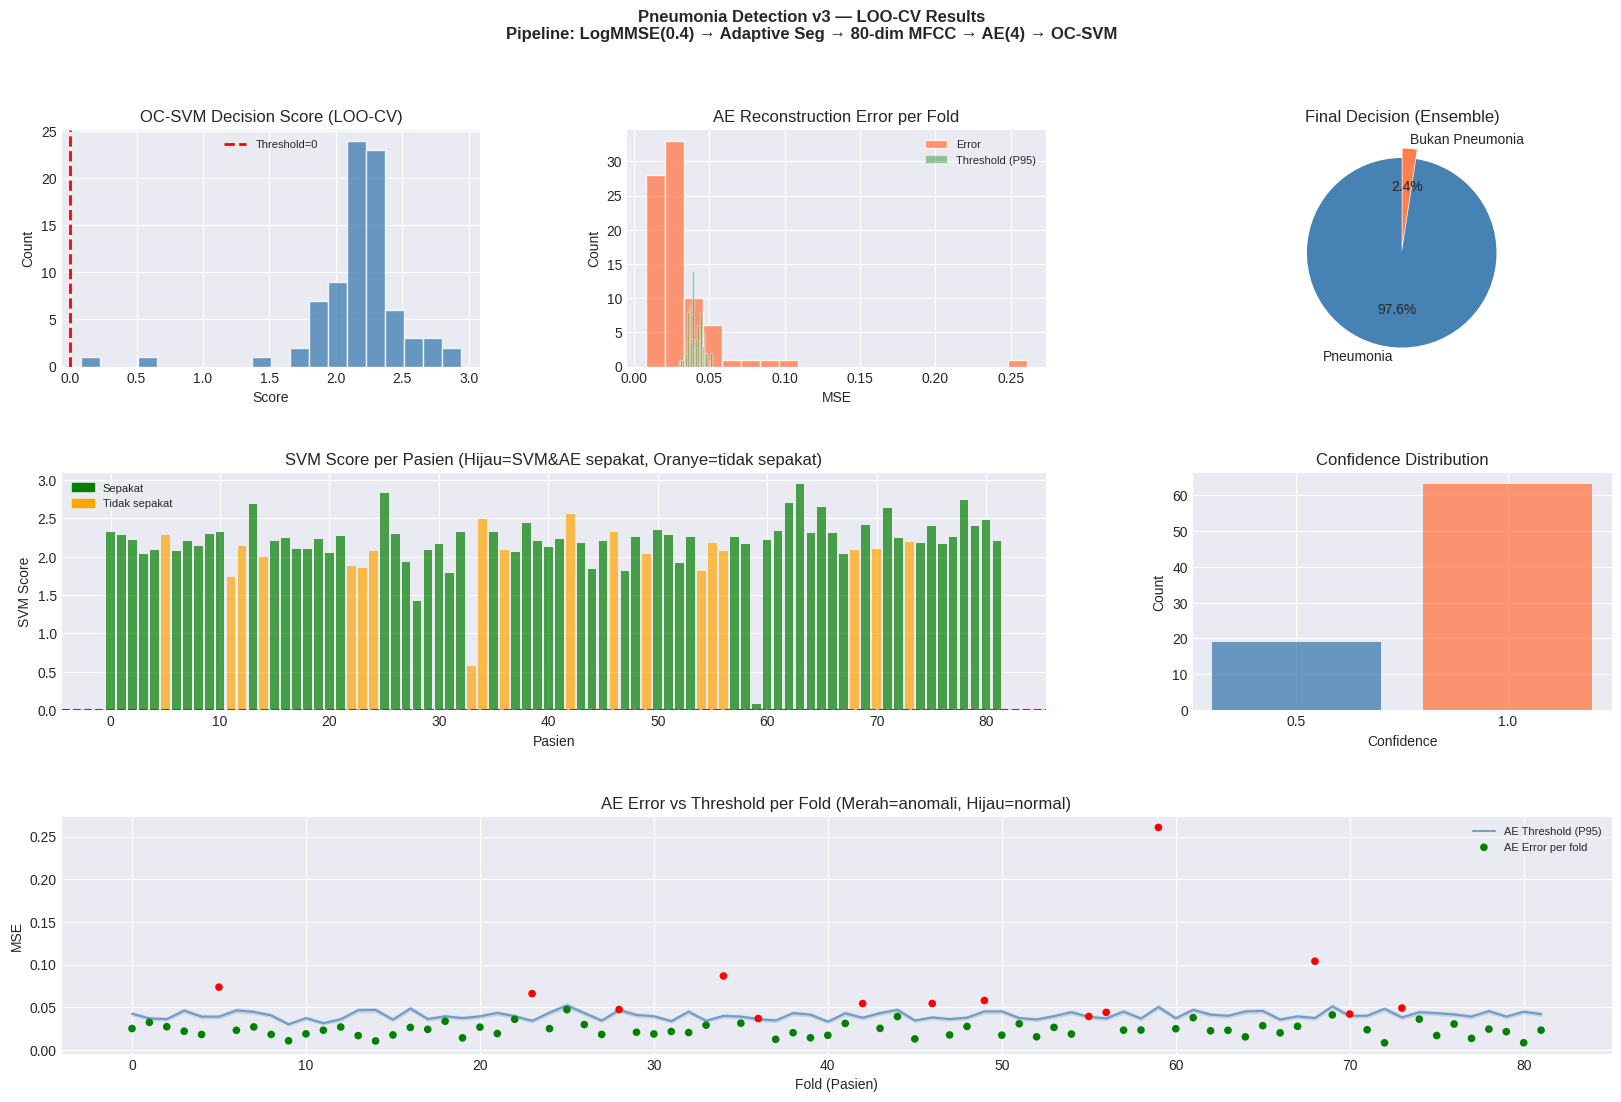

✅ Visualisasi LOO-CV disimpan


In [ ]:
# ─────────────────────────────────────────────
# CELL 17: VISUALISASI HASIL
# ─────────────────────────────────────────────
fig = plt.figure(figsize=(20, 12))
gs  = fig.add_gridspec(3, 3, hspace=0.45, wspace=0.35)
fig.suptitle(
    'Pneumonia Detection v3 — LOO-CV Results\n'
    'Pipeline: LogMMSE(0.4) → Adaptive Seg → 80-dim MFCC → AE(4) → OC-SVM',
    fontsize=12, fontweight='bold'
)

# 1. SVM Score distribution
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(df_loo['svm_score'], bins=20, color='steelblue', edgecolor='white', alpha=0.8)
ax1.axvline(0, color='red', linestyle='--', lw=2, label='Threshold=0')
ax1.set_title('OC-SVM Decision Score (LOO-CV)')
ax1.set_xlabel('Score')
ax1.set_ylabel('Count')
ax1.legend(fontsize=8)

# 2. AE error distribution
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(df_loo['ae_error'],    bins=20, color='coral', edgecolor='white', alpha=0.8, label='Error')
ax2.hist(df_loo['ae_threshold'], bins=20, color='green', edgecolor='white', alpha=0.4, label='Threshold (P95)')
ax2.set_title('AE Reconstruction Error per Fold')
ax2.set_xlabel('MSE')
ax2.set_ylabel('Count')
ax2.legend(fontsize=8)

# 3. Pie final label
ax3 = fig.add_subplot(gs[0, 2])
final_counts_plot = df_loo['final_label'].value_counts()
colors_pie = ['steelblue' if l == 'Pneumonia' else 'coral' for l in final_counts_plot.index]
ax3.pie(final_counts_plot.values, labels=final_counts_plot.index,
        autopct='%1.1f%%', colors=colors_pie,
        startangle=90, explode=[0.05]*len(final_counts_plot))
ax3.set_title('Final Decision (Ensemble)')

# 4. Agreement analysis
ax4 = fig.add_subplot(gs[1, :2])
agree_colors = ['green' if a else 'orange' for a in (df_loo['svm_label'] == df_loo['ae_label'])]
ax4.bar(range(len(df_loo)), df_loo['svm_score'], color=agree_colors, alpha=0.7)
ax4.axhline(0, color='red', linestyle='--', lw=1.5)
ax4.set_title('SVM Score per Pasien (Hijau=SVM&AE sepakat, Oranye=tidak sepakat)')
ax4.set_xlabel('Pasien')
ax4.set_ylabel('SVM Score')
green_p  = mpatches.Patch(color='green',  label='Sepakat')
orange_p = mpatches.Patch(color='orange', label='Tidak sepakat')
ax4.legend(handles=[green_p, orange_p], fontsize=8)

# 5. Confidence distribution
ax5 = fig.add_subplot(gs[1, 2])
conf_counts = df_loo['confidence'].value_counts().sort_index()
ax5.bar(conf_counts.index.astype(str), conf_counts.values,
        color=['steelblue', 'coral'], alpha=0.8)
ax5.set_title('Confidence Distribution')
ax5.set_xlabel('Confidence')
ax5.set_ylabel('Count')

# 6. AE threshold variance per fold
ax6 = fig.add_subplot(gs[2, :])
ax6.plot(df_loo['ae_threshold'], color='steelblue', lw=1.5, alpha=0.7, label='AE Threshold (P95)')
ax6.fill_between(range(len(df_loo)),
                 df_loo['ae_threshold'] * 0.95,
                 df_loo['ae_threshold'] * 1.05,
                 alpha=0.15, color='steelblue')
ax6.scatter(range(len(df_loo)),
            df_loo['ae_error'],
            c=['red' if e > t else 'green'
               for e, t in zip(df_loo['ae_error'], df_loo['ae_threshold'])],
            s=20, zorder=5, label='AE Error per fold')
ax6.set_title('AE Error vs Threshold per Fold (Merah=anomali, Hijau=normal)')
ax6.set_xlabel('Fold (Pasien)')
ax6.set_ylabel('MSE')
ax6.legend(fontsize=8)

plt.savefig(Config.OUTPUT_DIR / 'loo_cv_evaluation_v3.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Visualisasi LOO-CV disimpan")

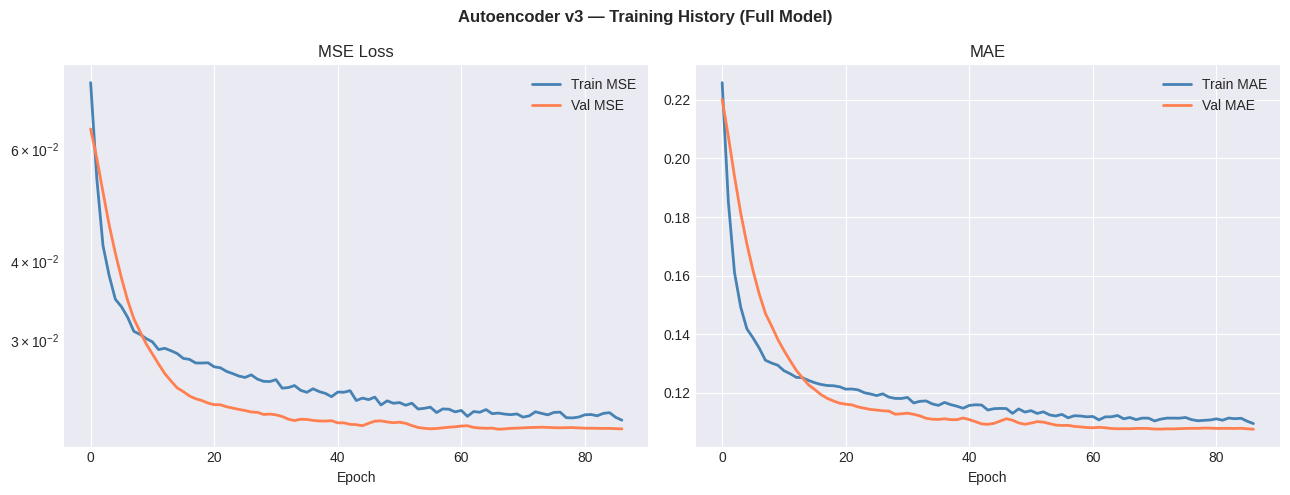

In [ ]:
# ─────────────────────────────────────────────
# CELL 18: TRAINING HISTORY (Full Model)
# ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Autoencoder v3 — Training History (Full Model)', fontsize=12, fontweight='bold')

axes[0].plot(history_full.history['loss'],     label='Train MSE', color='steelblue', lw=2)
axes[0].plot(history_full.history['val_loss'], label='Val MSE',   color='coral',    lw=2)
axes[0].set_title('MSE Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_yscale('log')
axes[0].legend()

axes[1].plot(history_full.history['mae'],      label='Train MAE', color='steelblue', lw=2)
axes[1].plot(history_full.history['val_mae'],  label='Val MAE',   color='coral',    lw=2)
axes[1].set_title('MAE')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.savefig(Config.OUTPUT_DIR / 'ae_training_v3.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
# ─────────────────────────────────────────────
# CELL 19: FUNGSI INFERENSI (Full Model)
# ─────────────────────────────────────────────
def predict_new_audio(
    filepath: str,
    encoder_model: Model,
    svm_model: OneClassSVM,
    feat_scaler: MinMaxScaler,
    latent_scaler: StandardScaler,
    ae_model: Model,
    ae_threshold: float,
    sr: int = Config.SAMPLE_RATE,
    verbose: bool = True
) -> Dict[str, Any]:
    """
    v3: Inferensi end-to-end untuk file audio baru.
    Pipeline: Audio → Preprocess → Segment → MFCC(80d) → AE(latent) → SVM
    """
    result = {
        'filepath': filepath, 'status': 'error',
        'n_chunks': 0,
        'svm_label': None, 'svm_score': None,
        'ae_label': None,  'ae_error': None,
        'ae_threshold': ae_threshold,
        'final_label': None, 'confidence': None
    }

    try:
        audio = preprocess_audio(filepath, sr)
        if audio is None:
            raise ValueError("Gagal memproses audio")

        chunks = segment_cough_chunks(audio, sr)
        result['n_chunks'] = len(chunks)

        # MFCC per chunk → aggregate
        mfcc_list = [extract_mfcc_matrix(c, sr) for c in chunks]
        min_T     = min(m.shape[1] for m in mfcc_list)
        mfcc_trim = [m[:, :min_T] for m in mfcc_list]
        agg       = aggregate_mfcc_chunks(mfcc_trim)
        feat      = mfcc_to_80dim_vector(agg).reshape(1, -1)

        # Scale features
        feat_scaled = feat_scaler.transform(feat)

        # AE reconstruction error
        feat_recon = ae_model.predict(feat_scaled, verbose=0)
        ae_error   = float(np.mean(np.square(feat_scaled - feat_recon)))
        ae_label   = "Pneumonia" if ae_error <= ae_threshold else "Bukan Pneumonia"

        # Latent → SVM
        latent        = encoder_model.predict(feat_scaled, verbose=0)
        latent_scaled = latent_scaler.transform(latent)
        svm_pred      = svm_model.predict(latent_scaled)[0]
        svm_score     = svm_model.score_samples(latent_scaled)[0]
        svm_label     = "Pneumonia" if svm_pred == 1 else "Bukan Pneumonia"

        # Ensemble
        votes = [svm_label, ae_label]
        n_p   = votes.count("Pneumonia")
        n_b   = votes.count("Bukan Pneumonia")
        final = "Pneumonia" if n_p >= n_b else "Bukan Pneumonia"
        conf  = max(n_p, n_b) / len(votes)

        result.update({
            'svm_label'  : svm_label,
            'svm_score'  : float(svm_score),
            'ae_label'   : ae_label,
            'ae_error'   : ae_error,
            'final_label': final,
            'confidence' : conf,
            'status'     : 'success'
        })

        if verbose:
            emoji = '🫁' if final == 'Pneumonia' else '✅'
            print(f"\n{'═'*58}")
            print(f"  📁 File   : {Path(filepath).name}")
            print(f"  🔪 Chunks : {len(chunks)} terdeteksi")
            print(f"{'─'*58}")
            print(f"  ① OC-SVM : {svm_label:<20s} (score: {svm_score:+.4f})")
            print(f"  ② AE     : {ae_label:<20s} (error: {ae_error:.6f} vs thr: {ae_threshold:.6f})")
            print(f"{'─'*58}")
            print(f"  {emoji} HASIL : {final} (confidence: {conf:.0%})")
            print(f"{'═'*58}")

    except Exception as e:
        logger.error(f"Error inferensi: {e}")
        result['error_msg'] = str(e)
        if verbose:
            print(f"❌ Error: {e}")

    return result

In [ ]:
# ─────────────────────────────────────────────
# CELL 20: DEMO INFERENSI
# ─────────────────────────────────────────────
print("🧪 Uji inferensi 3 sampel (full model)...\n")
for f in audio_files[:3]:
    predict_new_audio(
        str(f),
        encoder_model  = encoder_full,
        svm_model      = oc_svm_full,
        feat_scaler    = scaler_full,
        latent_scaler  = scaler_latent_full,
        ae_model       = autoencoder_full,
        ae_threshold   = ae_thresh_full
    )

🧪 Uji inferensi 3 sampel (full model)...


══════════════════════════════════════════════════════════
  📁 File   : P1.mp3
  🔪 Chunks : 1 terdeteksi
──────────────────────────────────────────────────────────
  ① OC-SVM : Pneumonia            (score: +2.3294)
  ② AE     : Pneumonia            (error: 0.013071 vs thr: 0.038908)
──────────────────────────────────────────────────────────
  🫁 HASIL : Pneumonia (confidence: 100%)
══════════════════════════════════════════════════════════

══════════════════════════════════════════════════════════
  📁 File   : P10.mp3
  🔪 Chunks : 1 terdeteksi
──────────────────────────────────────────────────────────
  ① OC-SVM : Pneumonia            (score: +2.2809)
  ② AE     : Pneumonia            (error: 0.024208 vs thr: 0.038908)
──────────────────────────────────────────────────────────
  🫁 HASIL : Pneumonia (confidence: 100%)
══════════════════════════════════════════════════════════

══════════════════════════════════════════════════════════
  📁 File 

In [ ]:
# ─────────────────────────────────────────────
# CELL 21: EKSPOR FINAL
# ─────────────────────────────────────────────
# Simpan encoder terpisah (untuk deployment ringan)
encoder_full.save(Config.MODEL_DIR / 'encoder_v3.h5')
autoencoder_full.save(Config.MODEL_DIR / 'autoencoder_full_v3_final.h5')

print("\n✅ Semua artefak disimpan:")
print(f"   {Config.MODEL_DIR / 'encoder_v3.h5'}")
print(f"   {Config.MODEL_DIR / 'autoencoder_full_v3_final.h5'}")
print(f"   {Config.MODEL_DIR / 'ocsvm_full_v3.pkl'}")
print(f"   {Config.MODEL_DIR / 'scaler_feat_v3.pkl'}")
print(f"   {Config.MODEL_DIR / 'scaler_latent_v3.pkl'}")
print(f"   {Config.MODEL_DIR / 'config_v3.pkl'}")
print(f"   {Config.OUTPUT_DIR / 'loo_cv_results_v3.csv'}")
print(f"   {Config.OUTPUT_DIR / 'loo_cv_evaluation_v3.png'}")
print(f"   {Config.OUTPUT_DIR / 'ae_training_v3.png'}")
print("\n🎉 Pipeline v3 selesai!")


✅ Semua artefak disimpan:
   /content/drive/MyDrive/Pneumonia Analysis/output_v3/models/encoder_v3.h5
   /content/drive/MyDrive/Pneumonia Analysis/output_v3/models/autoencoder_full_v3_final.h5
   /content/drive/MyDrive/Pneumonia Analysis/output_v3/models/ocsvm_full_v3.pkl
   /content/drive/MyDrive/Pneumonia Analysis/output_v3/models/scaler_feat_v3.pkl
   /content/drive/MyDrive/Pneumonia Analysis/output_v3/models/scaler_latent_v3.pkl
   /content/drive/MyDrive/Pneumonia Analysis/output_v3/models/config_v3.pkl
   /content/drive/MyDrive/Pneumonia Analysis/output_v3/loo_cv_results_v3.csv
   /content/drive/MyDrive/Pneumonia Analysis/output_v3/loo_cv_evaluation_v3.png
   /content/drive/MyDrive/Pneumonia Analysis/output_v3/ae_training_v3.png

🎉 Pipeline v3 selesai!


### 📦 Final Model Export and Reusable Inference
This section consolidates all artifacts needed for deployment (Scalers, Models, and Config) and provides a standalone function to load and run predictions.

In [1]:
import joblib
import tensorflow as tf
from pathlib import Path

def export_deployment_package():
    """Saves all necessary objects for standalone inference."""
    package_path = Config.MODEL_DIR / 'deployment_v3'
    package_path.mkdir(parents=True, exist_ok=True)

    # 1. Save Keras Models
    encoder_full.save(package_path / 'encoder_model.keras')
    autoencoder_full.save(package_path / 'autoencoder_model.keras')

    # 2. Save Scalers and SVM
    joblib.dump(scaler_full, package_path / 'feat_scaler.pkl')
    joblib.dump(scaler_latent_full, package_path / 'latent_scaler.pkl')
    joblib.dump(oc_svm_full, package_path / 'ocsvm_model.pkl')

    # 3. Save Config Metadata
    meta = {
        'ae_threshold': ae_thresh_full,
        'sample_rate': Config.SAMPLE_RATE,
        'n_mfcc': Config.N_MFCC,
        'feature_dim': Config.FEATURE_DIM,
        'version': '3.0'
    }
    joblib.dump(meta, package_path / 'metadata.pkl')

    print(f"✅ Deployment package saved to: {package_path}")

export_deployment_package()

NameError: name 'Config' is not defined

In [ ]:
def load_and_predict(audio_path):
    """Standalone function to load models from Drive and predict."""
    pkg = Config.MODEL_DIR / 'deployment_v3'

    # Load everything
    meta = joblib.load(pkg / 'metadata.pkl')
    scaler_feat = joblib.load(pkg / 'feat_scaler.pkl')
    scaler_lat = joblib.load(pkg / 'latent_scaler.pkl')
    svm = joblib.load(pkg / 'ocsvm_model.pkl')
    enc = tf.keras.models.load_model(pkg / 'encoder_model.keras')
    ae = tf.keras.models.load_model(pkg / 'autoencoder_model.keras')

    # Run prediction using the existing pipeline logic
    return predict_new_audio(
        audio_path, enc, svm, scaler_feat, scaler_lat, ae, meta['ae_threshold'],
        sr=meta['sample_rate'], verbose=True
    )

# Example usage:
result = load_and_predict(str(audio_files[0]))
print(result)